# 6단계 | DL과 PDF 원문 통합
- 기획서 v3.1의 표 위치 → PDF 문자·좌표 연결 단계 검증함
- 03 Notebook의 PyMuPDF 원문·좌표 파싱 방식과 05 Notebook의 탐지·구조 인식 모듈을 재사용함
- 개발용 T55·TCJ·TPB만 사용함. LLM 호출·규격값 확정·단위 정규화 수행하지 않음
- DL은 탐지 임계값 0.50·여백 2%·구조 임계값 0.50으로 실행함. 이전 결과와 일치 여부 별도 확인함
- 05단계에서 경계 글자 포함은 5표, 미탐지는 4표였음. 구조 인식이 헤더와 값 연결을 보장하지 않았음

In [1]:
from collections import Counter
from pathlib import Path
from time import perf_counter
import hashlib
import json
import os
import re

import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
import pymupdf
import torch
from PIL import Image
from IPython.display import display

from table_detection import (MODEL_NAME, MODEL_REVISION, STRUCTURE_MODEL_NAME, STRUCTURE_MODEL_REVISION,
    load_table_detector, load_structure_recognizer)
from datasheet_analysis import (WORD_FIELDS, DPI, DETECTION_THRESHOLD, PADDING_RATIO, STRUCTURE_THRESHOLD,
    bbox_of, center_of, word_ids_in_box, normalize_whitespace, extract_document_source,
    detect_page_regions, recognize_region_structure, associate_words, locate_part_occurrences,
    build_llm_input, estimate_input_size)

ROOT = Path.cwd()
assert (ROOT/'data/datasheet_manifest.csv').is_file()
font_path=Path('C:/Windows/Fonts/malgun.ttf')
assert font_path.is_file()
font_manager.fontManager.addfont(str(font_path))
plt.rcParams.update({'font.family':font_manager.FontProperties(fname=str(font_path)).get_name(),
                     'axes.unicode_minus':False})
torch.set_num_threads(min(4,os.cpu_count() or 1))
manifest=pd.read_csv(ROOT/'data/datasheet_manifest.csv',dtype=str).set_index('document_id')
splits=pd.read_csv(ROOT/'data/dataset_split.csv',dtype=str).set_index('document_id')
parts=pd.read_csv(ROOT/'data/part_numbers.csv',dtype=str)
selected={'vishay_t55':(1,5,15),'kyocera_avx_tcj':(1,6,7),'panasonic_tpb':(1,)}
targets=parts[parts.document_id.isin(selected)].copy()
assert targets.split.eq('dev').all() and not targets.duplicated(['document_id','part_number']).any()
for doc in selected:
    assert manifest.loc[doc,'split']==splits.loc[doc,'split']=='dev'
    assert targets[targets.document_id==doc].manufacturer.eq(manifest.loc[doc,'manufacturer']).all()
    assert targets[targets.document_id==doc].series.eq(manifest.loc[doc,'series']).all()
paths={doc:ROOT/'data/datasheets'/manifest.loc[doc,'filename'] for doc in selected}
hashes={doc:hashlib.sha256(path.read_bytes()).hexdigest() for doc,path in paths.items()}
display(targets[['document_id','part_number','split']])

,document_id,part_number,split
2,vishay_t55,T55A226M2R5C0200,dev
3,vishay_t55,T55A336M2R5C0200,dev
4,vishay_t55,T55B107M2R5C0070,dev
9,kyocera_avx_tcj,TCJU337M016R0050E,dev
10,kyocera_avx_tcj,TCJU337M016R0070E,dev
11,kyocera_avx_tcj,TCJU227M020R0070E,dev
12,kyocera_avx_tcj,TCJU107M025R0070E,dev
14,panasonic_tpb,4TPB68M,dev
15,panasonic_tpb,6TPB220ML,dev
16,panasonic_tpb,10TPB150ML,dev


## 원문 추출 및 입력 페이지 선택
- PDF 전체에서 CSV에 있는 P/N과 동일한 단어를 검색함. 부분 문자열·주문 코드 조합·OCR 보정 적용하지 않음
- 기존 DL 검증 5페이지와 원문 시리즈 조건이 있는 T55·TCJ p1을 입력에 포함함. 다른 페이지에 정확 일치가 있으면 함께 포함함
- page_text는 PDF 추출 순서, page_text_normalized는 공백만 접은 값임. 단어·블록 PDF point는 좌상단 원점임
- 좌표 정렬은 눈으로 읽는 순서와 같다고 가정하지 않음. 원문 추출 순서와 좌표 정렬이 다를 경우 경고함

In [2]:
page_sources, all_hits, scanned = {}, {}, {}
for doc,context in selected.items():
    source,hits,count=extract_document_source(paths[doc],doc,context,
        targets.loc[targets.document_id==doc,'part_number'].tolist())
    scanned[doc]=count
    all_hits[doc]=hits
    for n,page in source.items():
        page_sources[f'{doc}:p{n}']=page
for doc,hits in all_hits.items():
    for pn,items in hits.items():
        print(doc,pn,[(x['pdf_page'],x['word_id']) for x in items])
display(pd.DataFrame([{'document_id':doc,'pages_searched':count,
    'input_pages':[p['pdf_page'] for p in page_sources.values() if p['document_id']==doc]}
    for doc,count in scanned.items()]))

vishay_t55 T55A226M2R5C0200 [(5, 98)]
vishay_t55 T55A336M2R5C0200 [(5, 116)]
vishay_t55 T55B107M2R5C0070 [(5, 206)]
kyocera_avx_tcj TCJU337M016R0050E [(6, 329)]
kyocera_avx_tcj TCJU337M016R0070E [(6, 343)]
kyocera_avx_tcj TCJU227M020R0070E [(6, 737)]
kyocera_avx_tcj TCJU107M025R0070E [(7, 245)]
panasonic_tpb 4TPB68M [(1, 369)]
panasonic_tpb 6TPB220ML [(1, 412)]
panasonic_tpb 10TPB150ML [(1, 505)]


,document_id,pages_searched,input_pages
0,vishay_t55,30,"[1, 5, 15]"
1,kyocera_avx_tcj,13,"[1, 6, 7]"
2,panasonic_tpb,1,[1]


## 탐지 영역과 구조 후보 연결
- 기존 05 보완 CSV로 검증된 영역·미탐지 참조를 식별함. 두 모델 모두 캐시된 기존 커밋에서 실제 추론함
- 새 구조 후보는 5개 자동 crop에 대해 계산함. 기존 구조 실험 3개 crop은 좌표·점수 회귀 검사함
- 좌표는 crop 원시 픽셀 → crop 경계 제한 → 페이지 픽셀 → PDF point임. 페이지 원문 보존함
- 단어 중심과 겹치는 모든 행·열 ID를 보존함. 일대일 중심점만 교차 영역에 묶고, 여러 단어·값은 모두 유지함

In [3]:
refinement=pd.read_csv(ROOT/'results/05_dl_detection_refinement.csv')
baseline=refinement[(refinement.threshold==DETECTION_THRESHOLD)&(refinement.padding_ratio==PADDING_RATIO)]
structure_baseline=pd.read_csv(ROOT/'results/05_dl_structure_recognition.csv')
structure_baseline=structure_baseline[structure_baseline.input_type.eq('automatic_detection')]
cache=ROOT/'.venv/model_cache'
p,m,dev,detector_loading=load_table_detector(cache_dir=cache,local_files_only=True)
detector=(p,m,dev)
p,m,dev,structure_loading=load_structure_recognizer(cache_dir=cache,local_files_only=True)
recognizer=(p,m,dev)
for info in (detector_loading,structure_loading):
    assert all(k.endswith('.num_batches_tracked') for k in info.get('unexpected_keys',[]))
print('Device:',str(dev),'Torch:',torch.__version__,'Detection:',MODEL_REVISION,'Structure:',STRUCTURE_MODEL_REVISION)

header_end={('vishay_t55',5):142,('vishay_t55',15):116,('kyocera_avx_tcj',6):138,
            ('kyocera_avx_tcj',7):139,('panasonic_tpb',1):205}
header_terms={
    ('vishay_t55',5):{'capacitance':'CAPACITANCE','esr':'ESR','operating_temperature':'OPERATING'},
    ('kyocera_avx_tcj',6):{'rated_voltage':'Voltage','capacitance':'Capacitance','esr':'ESR'},
    ('kyocera_avx_tcj',7):{'rated_voltage':'Voltage','capacitance':'Capacitance','esr':'ESR'}
}
context_bands={
    ('vishay_t55',1):[('series_electrical_context',[50,358,285,450]),('series_note',[50,637,560,666])],
    ('vishay_t55',5):[('table_footnote',[50,698,560,729])],
    ('vishay_t55',15):[('test_conditions_footnote',[50,537,560,569])],
    ('kyocera_avx_tcj',1):[('series_technical_context',[25,621,580,735])],
    ('panasonic_tpb',1):[('specification_footnote',[50,759,550,779])]
}
disclaimer_bands={('kyocera_avx_tcj',6):[175,750,485,767],('kyocera_avx_tcj',7):[175,750,485,767]}
pn_patterns={'vishay_t55':r'T55[A-Z][A-Z0-9]{12}','kyocera_avx_tcj':r'TCJ[A-Z0-9#]{12,15}',
             'panasonic_tpb':r'\d+TPB[A-Z0-9]+'}
fallback_anchors={'dimensions':'W1±0.1','voltage_code':'10.0','capacitance_code':'N7',
                  'characteristics_list':'10TPB330M'}

def related_zone(page, category, bbox):
    """원문 위치에서 발췌한 문구와 단어 ID를 반환함."""
    ids=word_ids_in_box(page['words'],bbox)
    return {'category':category,'bbox_pdf':bbox,'word_ids':ids,
        'text':' '.join(page['words'][i][0] for i in ids)}

def register_tpb_hidden(page, path):
    """TPB p1에서 뒤의 배경에 가려진 코드 텍스트를 원문 좌표로 표시함."""
    with pymupdf.open(path) as doc:
        p=doc[0]
        cover_kind,cover_bbox=p.get_bboxlog()[252]
        assert cover_kind=='fill-path'
        spans=[s for s in p.get_texttrace() if s['seqno'] in {245,246,247,248}]
        assert spans and all(pymupdf.Rect(cover_bbox).contains(pymupdf.Rect(s['bbox'])) for s in spans)
        ids=set()
        for span in spans:
            text=''.join(chr(c[0]) for c in span['chars'])
            rect=pymupdf.Rect(span['bbox'])+(-1.5,-1.5,1.5,1.5)
            for i in word_ids_in_box(page['words'],list(rect)):
                if page['words'][i][0] in text:
                    ids.add(i)
    assert {'定格電圧','記号'} <= {page['words'][i][0] for i in ids}
    page['hidden_word_ids']=sorted(ids)
    page['hidden_review']={'status':'source_and_render_reviewed','cover_paint_sequence':252,
        'covered_span_sequences':[245,246,247,248],'cover_bbox_pdf':list(cover_bbox)}

images, render_meta, regression = {}, {}, []
for key,page in page_sources.items():
    doc,n=page['document_id'],page['pdf_page']
    k=(doc,n)
    words=page['words']
    page.update(table_regions=[],row_column_candidates=[],fallback_regions=[],
        detection_status='not_run_context',page_text_available=bool(page['page_text'].strip()),
        pn_like_word_ids=[i for i,w in enumerate(words) if re.fullmatch(pn_patterns[doc],w[0])])
    if page['source_order_differs_from_coordinate_sort']:
        page['warnings'].append('source_order_differs_from_coordinate_sort')
    if page['nonpainting_spans']:
        page['warnings'].append('nonpainting_text_spans')
    page['related_text']=[related_zone(page,label,bbox) for label,bbox in context_bands.get(k,[])]
    if k==('panasonic_tpb',1):
        register_tpb_hidden(page,paths[doc])
        page['warnings'].append('visually_occluded_source_text')
    prior=baseline[(baseline.document_id==doc)&(baseline.page==n)]
    if prior.empty:
        page['warnings'].append('series_context_only_no_dl')
        continue
    image,meta,regions,det_time=detect_page_regions(paths[doc],n,detector)
    images[key],render_meta[key]=image,meta
    page['detection_status']='detected' if regions else 'not_detected'
    page['detection_timing']=det_time
    page['render_dpi']=DPI
    page['render_size_pixels']=list(image.size)
    assert len(regions)==prior.original_bbox.notna().sum()
    for saved in prior.itertuples():
        assert saved.source_pdf_sha256==hashes[doc] and saved.model_revision==MODEL_REVISION
        if saved.detection_status=='undetected':
            ref=json.loads(saved.reference_window_pdf)
            ids=word_ids_in_box(words,ref)
            visible=[i for i in ids if i not in page['hidden_word_ids']]
            anchor=fallback_anchors[saved.table_id]
            anchor_ids=[i for i in visible if words[i][0]==anchor]
            assert anchor_ids
            page['fallback_regions'].append({'table_id':saved.table_id,'detection_status':'not_detected',
                'source_text_available':bool(visible),'reference_bbox_pdf':ref,'word_ids':ids,
                'visible_word_ids':visible,'reviewed_anchor_word_ids':anchor_ids,
                'source_route':'page_text_only','structure_restored':False})
            continue
        region=next(r for r in regions if np.allclose(r['original_bbox_pixels'],
            json.loads(saved.original_bbox),atol=.05,rtol=0))
        assert np.allclose(region['expanded_bbox_pixels'],json.loads(saved.expanded_bbox),atol=.05,rtol=0)
        assert abs(region['confidence']-saved.confidence)<1e-6
        ids=word_ids_in_box(words,region['expanded_bbox_pdf'])
        rect=pymupdf.Rect(region['expanded_bbox_pdf'])
        ref=json.loads(saved.reference_window_pdf)
        header_ids=[i for i in word_ids_in_box(words,ref) if center_of(words[i])[1]<header_end[k]]
        region.update(table_id=saved.table_id,word_ids=ids,source_text_available=bool(ids),
            source_text=' '.join(words[i][0] for i in ids),reviewed_header_word_ids=header_ids,
            crop_edge_word_ids=[i for i in ids if not rect.contains(pymupdf.Rect(bbox_of(words[i])))],
            header_in_crop_verified=bool(saved.header_included),
            unrelated_content_in_crop=bool(saved.unrelated_content_included))
        raw_rect=pymupdf.Rect(region['original_bbox_pdf'])
        region['original_header_clipped_word_ids']=[i for i in header_ids if not raw_rect.contains(pymupdf.Rect(bbox_of(words[i])))]
        if k in disclaimer_bands:
            region['unrelated_word_ids']=[i for i in word_ids_in_box(words,disclaimer_bands[k]) if i in ids]
        if region['unrelated_content_in_crop']:
            page['warnings'].append('unrelated_disclaimer_in_table_crop')
        page['table_regions'].append(region)
        regression.append((key,'detection'))
        structure=recognize_region_structure(image,meta,region,recognizer)
        objects=structure['objects']
        membership,cells=associate_words(words,[i for i in ids if i not in page['hidden_word_ids']],objects)
        header_objs=[o for o in objects if o['label']=='table column header']
        missed_header=min((sum(not pymupdf.Rect(o['bbox_pdf']).contains(pymupdf.Rect(bbox_of(words[i])))
            for i in header_ids) for o in header_objs),default=len(header_ids))
        by_word={i:(rr,cc) for i,rr,cc in membership}
        header_hints=[]
        for field,token in header_terms.get(k,{}).items():
            found=[i for i in header_ids if words[i][0]==token]
            header_hints.append({'field_hint':field,'word_ids':found,
                'column_ids':sorted({c for i in found for c in by_word.get(i,([],[]))[1]}),
                'scope':'literal_header_anchor_only'})
        structure.update(table_id=region['table_id'],word_membership=membership,cell_candidates=cells,
            header_missing_word_count=missed_header,header_candidates_detected=bool(header_objs),
            header_column_hints=header_hints,status='location_candidates_only')
        if missed_header:
            page['warnings'].append('structure_header_incomplete')
        if any(o['label'] in ('table spanning cell','table projected row header') for o in objects):
            page['warnings'].append('merged_or_group_header_unverified')
        if any(len(rr)>1 or len(cc)>1 for _,rr,cc in membership):
            page['warnings'].append('overlapping_row_or_column_candidates')
        page['row_column_candidates'].append(structure)
        existing=structure_baseline[(structure_baseline.document_id==doc)&(structure_baseline.page==n)&
            (structure_baseline.table_id==region['table_id'])]
        if not existing.empty:
            old_objects=json.loads(existing.iloc[0].objects_json)
            assert len(old_objects)==len(objects)
            for a,b in zip(old_objects,objects):
                assert a['label']==b['label'] and abs(a['confidence']-b['confidence'])<1e-6
                assert np.allclose(a['bbox_pdf'],b['bbox_pdf'],atol=.05,rtol=0)
            regression.append((key,'structure'))
    if page['fallback_regions']:
        page['warnings'].append('detection_miss_page_text_fallback')
    page['warnings']=sorted(set(page['warnings']))
assert Counter(kind for _,kind in regression)=={'detection':5,'structure':3}
display(pd.DataFrame([{'page_key':key,'status':p['detection_status'],'table_regions':len(p['table_regions']),
    'structures':len(p['row_column_candidates']),'fallback':len(p['fallback_regions']),
    'warnings':', '.join(p['warnings'])} for key,p in page_sources.items()]))

Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

[transformers] TableTransformerForObjectDetection LOAD REPORT from: microsoft/table-transformer-detection
Key                                                                         | Status     |  | 
----------------------------------------------------------------------------+------------+--+-
model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

[transformers] TableTransformerForObjectDetection LOAD REPORT from: microsoft/table-transformer-structure-recognition
Key                                                                         | Status     |  | 
----------------------------------------------------------------------------+------------+--+-
model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cpu Torch: 2.15.0+cpu Detection: 2357cbe2b5a5d1c03e54f32764f06058933b65ab Structure: f4d4bdc85c3fe4b1fa49658882a5d38bbdd0f343


,page_key,status,table_regions,structures,fallback,warnings
0,vishay_t55:p1,not_run_context,0,0,0,"source_order_differs_from_coordinate_sort, ser..."
1,vishay_t55:p5,detected,1,1,0,"merged_or_group_header_unverified, overlapping..."
2,vishay_t55:p15,detected,1,1,0,"merged_or_group_header_unverified, overlapping..."
3,kyocera_avx_tcj:p1,not_run_context,0,0,0,"source_order_differs_from_coordinate_sort, ser..."
4,kyocera_avx_tcj:p6,detected,1,1,0,"merged_or_group_header_unverified, overlapping..."
5,kyocera_avx_tcj:p7,detected,1,1,0,"merged_or_group_header_unverified, overlapping..."
6,panasonic_tpb:p1,detected,1,1,4,"detection_miss_page_text_fallback, merged_or_g..."


## P/N 등장 위치와 미탐지 보조 경로
- 같은 페이지에서 P/N 글자의 좌표와 모든 구조 후보를 기록함. 다른 P/N 형태의 원문 단어가 같은 후보 행을 공유하면 모호로 기록함
- P/N 패턴은 충돌 확인에만 사용함. 주문 코드의 의미를 해석하지 않음
- TPB 미탐지 4표에는 페이지 원문과 시각 확인 영역의 단어 참조를 제공함. 구조 복원 상태는 false임
- 면책문, 관련 각주, 가려진 텍스트를 분리 표시함. 원문은 삭제하지 않음

In [4]:
samples=[]
for part in targets.itertuples():
    doc,pn=part.document_id,part.part_number
    occurrences=locate_part_occurrences(all_hits[doc][pn],page_sources)
    context_pages={f'{doc}:p{n}' for n in selected[doc] if
                   n==1 or (doc=='vishay_t55' and n==15)}
    page_refs=sorted(context_pages|{x['page_key'] for x in occurrences},
                     key=lambda key:page_sources[key]['pdf_page'])
    samples.append({'document_id':doc,'manufacturer':part.manufacturer,'series':part.series,'part_number':pn,
        'page_refs':page_refs,'occurrences':occurrences,
        'pn_search_status':'found_exact' if occurrences else 'not_found_exact'})
pn_audit=pd.DataFrame([{'document_id':s['document_id'],'part_number':s['part_number'],
    'pdf_pages':[o['pdf_page'] for o in s['occurrences']],
    'geometry_status':[o['geometry_status'] for o in s['occurrences']]} for s in samples])
display(pn_audit)
tpb=page_sources['panasonic_tpb:p1']
for fallback in tpb['fallback_regions']:
    print(fallback['table_id'],fallback['detection_status'],
        [(tpb['words'][i][0],bbox_of(tpb['words'][i])) for i in fallback['reviewed_anchor_word_ids']])
print('TPB 각주:',tpb['related_text'][0]['text'])
print('TPB 가려진 텍스트:',[tpb['words'][i][0] for i in tpb['hidden_word_ids']])

,document_id,part_number,pdf_pages,geometry_status
0,vishay_t55,T55A226M2R5C0200,[5],[unique_geometry_candidate]
1,vishay_t55,T55A336M2R5C0200,[5],[unique_geometry_candidate]
2,vishay_t55,T55B107M2R5C0070,[5],[unique_geometry_candidate]
3,kyocera_avx_tcj,TCJU337M016R0050E,[6],[missing_axis_candidate]
4,kyocera_avx_tcj,TCJU337M016R0070E,[6],[missing_axis_candidate]
5,kyocera_avx_tcj,TCJU227M020R0070E,[6],[ambiguous_geometry]
6,kyocera_avx_tcj,TCJU107M025R0070E,[7],[ambiguous_geometry]
7,panasonic_tpb,4TPB68M,[1],[fallback_source_only]
8,panasonic_tpb,6TPB220ML,[1],[fallback_source_only]
9,panasonic_tpb,10TPB150ML,[1],[fallback_source_only]


dimensions not_detected [('W1±0.1', [503.5594177246094, 503.8091735839844, 531.5194702148438, 511.8091735839844])]
voltage_code not_detected [('10.0', [270.3604431152344, 497.8102111816406, 284.9554748535156, 505.3102111816406])]
capacitance_code not_detected [('N7', [233.17999267578125, 547.2200927734375, 242.76498413085938, 554.7200927734375])]
characteristics_list not_detected [('10TPB330M', [455.0747985839844, 749.0846557617188, 496.34735107421875, 756.5846557617188])]
TPB 각주: ✽1 Ripple current (100 kHz/ +45 °C ), ✽2 ESR (100 kHz/+20 °C) ✽3 tan d (120 Hz/+20 °C) ✽4 After 5 minutes ◆ Please refer to each page in this catarog for “Reflow conditions” and “Taping specifications”.
TPB 가려진 텍스트: ['定格電圧', '(V.DC)', '2.0', '2.5', '4.0', '6.3', '10.0', '記号', 'd', 'e', 'g', 'j', 'A']


## LLM 입력 묶음과 검증용 집계
- 원문·전체 좌표는 page_sources에 페이지별로 한 번 저장함. samples는 P/N, 문서, 등장 위치, page_refs를 가짐
- build_llm_input으로 pages 배열의 단일 요청 입력을 구성할 수 있음. 기본 입력은 전체 페이지 원문을 보존하고 P/N에 관련된 행 후보 위주로 좌표를 가져옴. 전체 좌표도 선택 가능함
- 표 영역 source_text와 관련 문구 text는 원문 단어를 추출 순서대로 공백 결합한 보기임. 정확한 줄바꿈이 필요한 경우 page_text와 블록 원문 사용함
- 우선순위나 규격값은 확정하지 않음. 둘 이상의 행·열이 겹치거나 한 셀에 여러 단어가 있으면 후보를 보존함
- 추정 토큰은 UTF-8 바이트/4 올림임. 실제 모델 토크나이저나 비용 계산이 아님

In [5]:
bundle={'schema_version':'1.0','stage':'06_dl_pdf_integration','word_fields':WORD_FIELDS,
    'membership_fields':['word_id','row_candidate_ids','column_candidate_ids'],
    'input_policy':{'status':'evidence_candidates_only','coordinate_system':'PDF point, top-left, 1-based physical page',
        'reading_order':'PDF extraction order; not verified as visual reading order',
        'occluded_text':'preserved in raw page text; exclude annotated hidden_word_ids from evidence',
        'fallback':'PDF text only, not a recovered DL table',
        'ambiguity':'keep every candidate; do not infer missing values or decode part numbers',
        'no_llm_call':True},
    'models':{'detection':{'name':MODEL_NAME,'revision':MODEL_REVISION,'threshold':DETECTION_THRESHOLD,
                          'padding_ratio':PADDING_RATIO,'dpi':DPI,'device':str(detector[2])},
              'structure':{'name':STRUCTURE_MODEL_NAME,'revision':STRUCTURE_MODEL_REVISION,
                           'threshold':STRUCTURE_THRESHOLD,'device':str(recognizer[2])}},
    'documents':[{ 'document_id':doc,'manufacturer':manifest.loc[doc,'manufacturer'],
        'series':manifest.loc[doc,'series'],'filename':paths[doc].name,'pdf_sha256':hashes[doc],
        'split':'dev','scanned_pages':scanned[doc]} for doc in selected],
    'samples':samples,'page_sources':page_sources}
for s in samples:
    payload=build_llm_input(bundle,s['document_id'],s['part_number'])
    s['input_size']=estimate_input_size(payload)
    s['input_size']['raw_page_text_characters']=sum(len(p['page_text']) for p in payload['pages'])
    assert all(p['page_text'] for p in payload['pages'])
print('공유 JSON 크기:',estimate_input_size(bundle))
display(pd.DataFrame([{'document_id':s['document_id'],'part_number':s['part_number'],**s['input_size']}
                       for s in samples]))

summary_records=[]
for key,page in page_sources.items():
    doc=page['document_id']
    hit_list=[x for s in samples for x in s['occurrences'] if x['page_key']==key]
    regions=page['table_regions']
    structures=page['row_column_candidates']
    status=Counter(x['geometry_status'] for x in hit_list)
    summary_records.append(dict(document_id=doc,pdf_page=page['pdf_page'],
        page_key=key,pages_searched_document=scanned[doc],detection_status=page['detection_status'],
        page_text_available=page['page_text_available'],page_text_characters=len(page['page_text']),
        pn_occurrences=len(hit_list),distinct_pn_found=len({x['text'] for x in hit_list}),
        unique_geometry_candidates=status['unique_geometry_candidate'],
        pn_geometry_ambiguous=status['ambiguous_geometry']+status['ambiguous_region'],
        pn_source_only=sum(v for k,v in status.items() if k not in
                           {'unique_geometry_candidate','ambiguous_geometry','ambiguous_region'}),
        table_regions=len(regions),table_text_regions=sum(r['source_text_available'] for r in regions),
        structure_regions=len(structures),structure_linked_regions=sum(bool(r['cell_candidates']) for r in structures),
        structure_cell_candidates=sum(len(r['cell_candidates']) for r in structures),
        structure_header_incomplete=sum(r['header_missing_word_count']>0 for r in structures),
        unrelated_crop_regions=sum(r['unrelated_content_in_crop'] for r in regions),
        reading_order_differs=page['source_order_differs_from_coordinate_sort'],
        hidden_words=len(page['hidden_word_ids']),nonpainting_spans=len(page['nonpainting_spans']),
        related_zones=len(page['related_text']),fallback_tables=len(page['fallback_regions']),
        fallback_with_text=sum(r['source_text_available'] for r in page['fallback_regions']),
        detection_seconds=page.get('detection_timing',{}).get('processing_seconds'),
        structure_seconds=sum(r['timing']['processing_seconds'] for r in structures) if structures else None,
        warnings=';'.join(page['warnings'])))
summary=pd.DataFrame(summary_records)
display(summary)

공유 JSON 크기: {'json_characters': 1013069, 'json_utf8_bytes': 1015328, 'estimated_tokens_utf8_bytes_div4': 253832}


,document_id,part_number,json_characters,json_utf8_bytes,estimated_tokens_utf8_bytes_div4,raw_page_text_characters
0,vishay_t55,T55A226M2R5C0200,75912,76087,19022,8346
1,vishay_t55,T55A336M2R5C0200,75923,76098,19025,8346
2,vishay_t55,T55B107M2R5C0070,75919,76094,19024,8346
3,kyocera_avx_tcj,TCJU337M016R0050E,55883,56194,14049,10234
4,kyocera_avx_tcj,TCJU337M016R0070E,55883,56194,14049,10234
5,kyocera_avx_tcj,TCJU227M020R0070E,61031,61344,15336,10234
6,kyocera_avx_tcj,TCJU107M025R0070E,59836,60133,15034,10163
7,panasonic_tpb,4TPB68M,49480,49669,12418,3334
8,panasonic_tpb,6TPB220ML,49484,49673,12419,3334
9,panasonic_tpb,10TPB150ML,49486,49675,12419,3334


,document_id,pdf_page,page_key,pages_searched_document,detection_status,page_text_available,page_text_characters,pn_occurrences,distinct_pn_found,unique_geometry_candidates,...,unrelated_crop_regions,reading_order_differs,hidden_words,nonpainting_spans,related_zones,fallback_tables,fallback_with_text,detection_seconds,structure_seconds,warnings
0,vishay_t55,1,vishay_t55:p1,30,not_run_context,True,2195,0,0,0,...,0,True,0,0,2,0,0,NaN,NaN,source_order_differs_from_coordinate_sort;seri...
1,vishay_t55,5,vishay_t55:p5,30,detected,True,3432,3,3,3,...,0,True,0,0,1,0,0,2.404191,0.870405,merged_or_group_header_unverified;overlapping_...
2,vishay_t55,15,vishay_t55:p15,30,detected,True,2719,0,0,0,...,0,True,0,0,1,0,0,0.510482,0.870257,merged_or_group_header_unverified;overlapping_...
3,kyocera_avx_tcj,1,kyocera_avx_tcj:p1,13,not_run_context,True,4733,0,0,0,...,0,True,0,0,1,0,0,NaN,NaN,source_order_differs_from_coordinate_sort;seri...
4,kyocera_avx_tcj,6,kyocera_avx_tcj:p6,13,detected,True,5501,3,3,0,...,1,True,0,0,0,0,0,0.522175,0.858311,merged_or_group_header_unverified;overlapping_...
5,kyocera_avx_tcj,7,kyocera_avx_tcj:p7,13,detected,True,5430,1,1,0,...,1,True,0,0,0,0,0,0.503745,0.886537,merged_or_group_header_unverified;overlapping_...
6,panasonic_tpb,1,panasonic_tpb:p1,1,detected,True,3334,3,3,0,...,0,True,13,0,1,4,4,0.492996,0.468468,detection_miss_page_text_fallback;merged_or_gr...


## 원문·좌표 대조와 시각화
- 세 제조사의 P/N 등장 예시를 같은 원본 페이지 좌표에 표시함. 주황은 탐지 후보, 빨강·파랑은 구조 행·열, 녹색은 CSV의 P/N, 보라 점선은 미탐지 원문 보조 범위임
- 그림은 위치 증거를 제시함. 상자가 글자와 겹쳐도 확정된 규격 셀을 뜻하지 않음

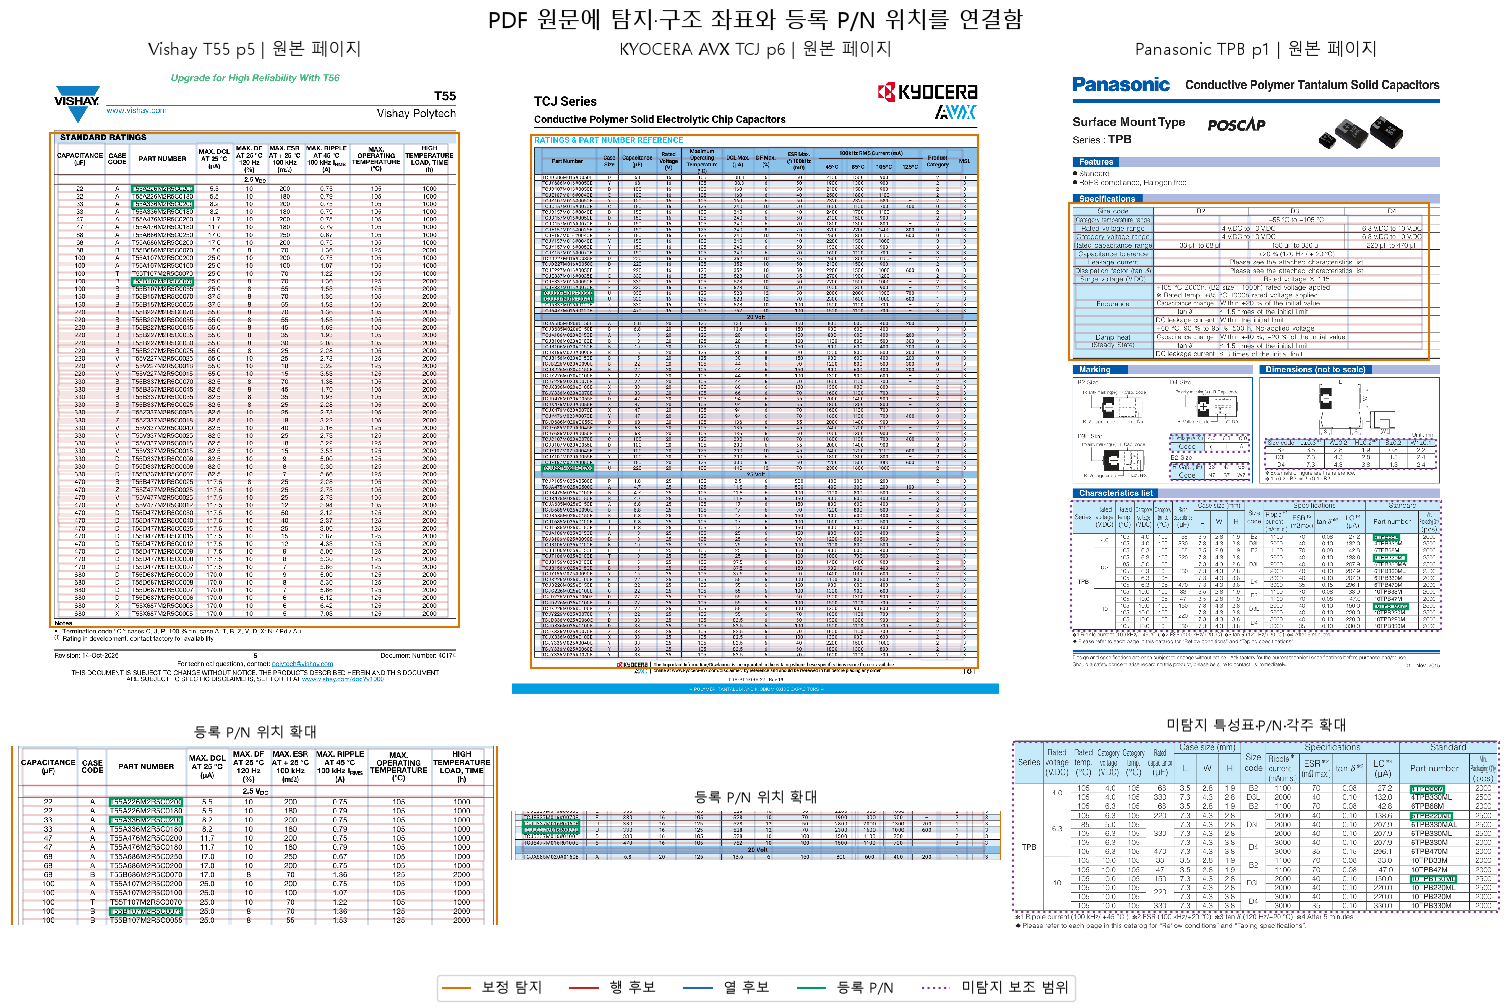

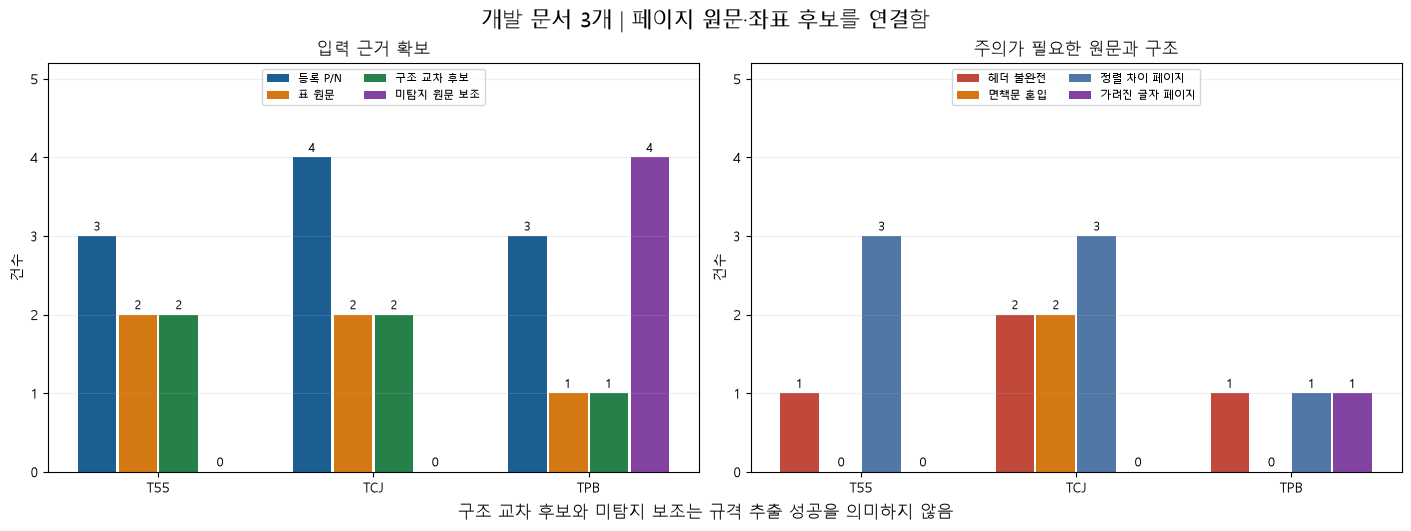

In [6]:
def add_box(axis,bbox,color,style='-',width=1.0,alpha=1.0):
    """PDF 좌표 상자를 지정한 색으로 겹쳐 그림."""
    x0,y0,x1,y1=bbox
    axis.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,
        edgecolor=color,linestyle=style,linewidth=width,alpha=alpha))

def draw_source(axis,key,zoom=False):
    """페이지 원본 및 P/N·탐지·구조·보조 위치를 표시함."""
    source=page_sources[key]
    x0,y0,x1,y1=source['page_bbox_pdf']
    axis.imshow(images[key],extent=(x0,x1,y1,y0),interpolation='none')
    for r in source['table_regions']:
        add_box(axis,r['expanded_bbox_pdf'],'#d67805','-',1.5)
    for st in source['row_column_candidates']:
        for obj in st['objects']:
            if obj['label'] in {'table row','table column'}:
                add_box(axis,obj['bbox_pdf'],'#b62a21' if obj['label']=='table row' else '#2366bb',
                        '-',.35,.5)
    for r in source['fallback_regions']:
        add_box(axis,r['reference_bbox_pdf'],'#78369b',':',1.5)
    for hit in [h for s in samples for h in s['occurrences'] if h['page_key']==key]:
        add_box(axis,hit['bbox_pdf'],'#009966','-',1.7)
    if zoom:
        ranges={'vishay_t55:p5':(45,98,566,288),'kyocera_avx_tcj:p6':(23,274,585,330),
                'panasonic_tpb:p1':(48,582,547,778)}
        a,b,c,d=ranges[key]
        axis.set_xlim(a,c)
        axis.set_ylim(d,b)
    axis.axis('off')

examples_path=ROOT/'outputs/06_dl_pdf_integration_examples.png'
coverage_path=ROOT/'outputs/06_llm_input_coverage.png'
fig,axes=plt.subplots(2,3,figsize=(15,10),layout='constrained',height_ratios=[2.4,1])
for j,(key,label) in enumerate([('vishay_t55:p5','Vishay T55 p5'),
        ('kyocera_avx_tcj:p6','KYOCERA AVX TCJ p6'),('panasonic_tpb:p1','Panasonic TPB p1')]):
    draw_source(axes[0,j],key)
    axes[0,j].set_title(label+' | 원본 페이지')
    draw_source(axes[1,j],key,True)
    axes[1,j].set_title(('등록 P/N 위치 확대' if j<2 else '미탐지 특성표·P/N·각주 확대'),fontsize=10)
fig.legend(handles=[Line2D([],[],color=color,ls=style,label=label) for color,style,label in
    [('#d67805','-','보정 탐지'),('#b62a21','-','행 후보'),('#2366bb','-','열 후보'),
     ('#009966','-','등록 P/N'),('#78369b',':','미탐지 보조 범위')]],loc='outside lower center',ncol=5)
fig.suptitle('PDF 원문에 탐지·구조 좌표와 등록 P/N 위치를 연결함',fontsize=16)
fig.savefig(examples_path,dpi=180)
plt.show()
plt.close(fig)

doc_counts=summary.groupby('document_id',sort=False)[['table_text_regions','structure_linked_regions',
    'fallback_with_text','structure_header_incomplete','unrelated_crop_regions','reading_order_differs']].sum().reindex(selected)
doc_counts['pn_found']=[sum(s['pn_search_status']=='found_exact' for s in samples if s['document_id']==doc)
                       for doc in selected]
doc_counts['pn_total']=[sum(s['document_id']==doc for s in samples) for doc in selected]
doc_counts['hidden_pages']=[sum(bool(p['hidden_word_ids'] or p['nonpainting_spans'])
    for p in page_sources.values() if p['document_id']==doc) for doc in selected]
fig,axes=plt.subplots(1,2,figsize=(14,5.2),layout='constrained')
x=np.arange(len(selected))
for ax,title,metrics in [
    (axes[0],'입력 근거 확보',[('pn_found','등록 P/N','#1b5e91'),('table_text_regions','표 원문','#d47813'),
        ('structure_linked_regions','구조 교차 후보','#26804a'),('fallback_with_text','미탐지 원문 보조','#8242a2')]),
    (axes[1],'주의가 필요한 원문과 구조',[('structure_header_incomplete','헤더 불완전','#c1493b'),
        ('unrelated_crop_regions','면책문 혼입','#d47813'),('reading_order_differs','정렬 차이 페이지','#5077a6'),
        ('hidden_pages','가려진 글자 페이지','#8242a2')])]:
    for i,(col,label,color) in enumerate(metrics):
        bars=ax.bar(x+(i-1.5)*.19,doc_counts[col],.18,label=label,color=color)
        ax.bar_label(bars,padding=2,fontsize=9)
    ax.set_xticks(x,['T55','TCJ','TPB'])
    ax.set_ylim(0,5.2)
    ax.set_ylabel('건수')
    ax.set_title(title)
    ax.legend(ncol=2,fontsize=8,loc='upper center')
    ax.grid(axis='y',alpha=.2)
fig.suptitle('개발 문서 3개 | 페이지 원문·좌표 후보를 연결함',fontsize=15)
fig.supxlabel('구조 교차 후보와 미탐지 보조는 규격 추출 성공을 의미하지 않음')
fig.savefig(coverage_path,dpi=180)
plt.show()
plt.close(fig)

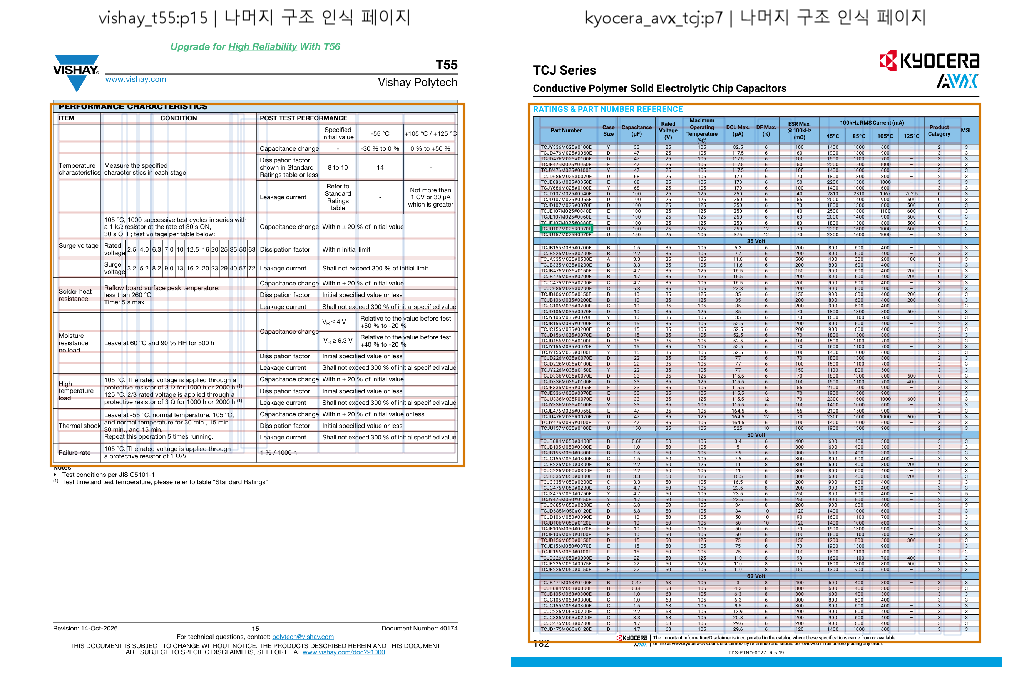

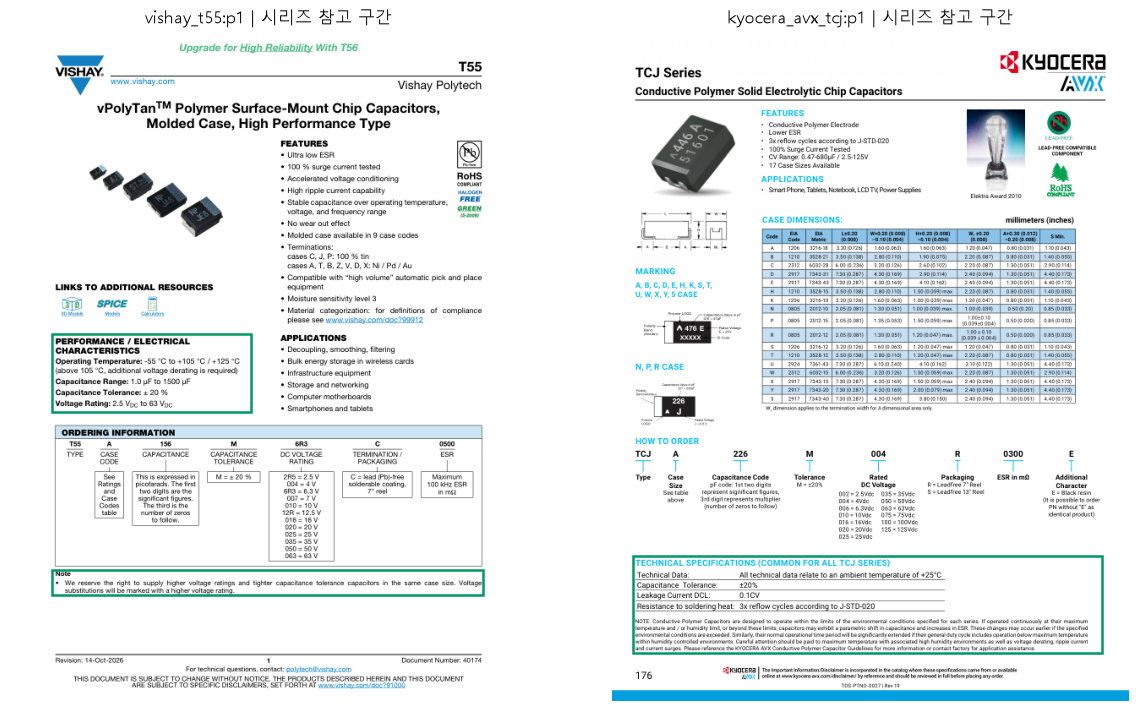

In [7]:
fig,axes=plt.subplots(1,2,figsize=(10,7),layout='constrained')
for ax,key in zip(axes,['vishay_t55:p15','kyocera_avx_tcj:p7']):
    draw_source(ax,key)
    ax.set_title(key+' | 나머지 구조 인식 페이지')
plt.show()
plt.close(fig)

fig,axes=plt.subplots(1,2,figsize=(12,7),layout='constrained')
for ax,key in zip(axes,['vishay_t55:p1','kyocera_avx_tcj:p1']):
    source=page_sources[key]
    with pymupdf.open(paths[source['document_id']]) as doc:
        pixmap=doc[0].get_pixmap(matrix=pymupdf.Matrix(1,1),alpha=False)
        page_image=Image.frombytes('RGB',(pixmap.width,pixmap.height),pixmap.samples)
    x0,y0,x1,y1=source['page_bbox_pdf']
    ax.imshow(page_image,extent=(x0,x1,y1,y0))
    for zone in source['related_text']:
        add_box(ax,zone['bbox_pdf'],'#009966','-',1.8)
    ax.set_title(key+' | 시리즈 참고 구간')
    ax.axis('off')
plt.show()
plt.close(fig)

## 파일 저장 및 원문 재대조
- 자동 검사: 파일 재읽기, PDF 원문·단어·블록 좌표 비교, P/N 전체 페이지 재검색, 좌표 왕복, 모든 후보 참조 확인함
- 시각 대조: P/N 상자, 표 경계, TCJ 하단 면책문, TPB 미탐지 4표 및 각주와 숨겨진 텍스트를 확인함
- 셀의 숫자와 P/N을 확정하지 않음. 미탐지 표의 구조 및 최종 LLM 응답은 미검증임

In [8]:
json_path=ROOT/'results/06_llm_input_samples.json'
csv_path=ROOT/'results/06_integration_summary.csv'
json_path.write_text(json.dumps(bundle,ensure_ascii=False,separators=(',',':'),allow_nan=False),encoding='utf-8')
summary.to_csv(csv_path,index=False,encoding='utf-8-sig')
saved=json.loads(json_path.read_text(encoding='utf-8'))
readback=pd.read_csv(csv_path)
assert saved==bundle and len(readback)==len(page_sources)
assert len(saved['samples'])==len(targets) and set(saved['page_sources'])==set(page_sources)
for source_record in saved['documents']:
    doc=source_record['document_id']
    assert source_record['pdf_sha256']==hashlib.sha256(paths[doc].read_bytes()).hexdigest()
    sample_subset=[s for s in saved['samples'] if s['document_id']==doc]
    with pymupdf.open(paths[doc]) as pdf:
        assert len(pdf)==source_record['scanned_pages']
        rescanned=Counter((n,w[4]) for n,page in enumerate(pdf,1) for w in page.get_text('words')
            if w[4] in {s['part_number'] for s in sample_subset})
        assert rescanned==Counter((o['pdf_page'],s['part_number']) for s in sample_subset for o in s['occurrences'])
        for key,source in saved['page_sources'].items():
            if source['document_id']!=doc:
                continue
            page=pdf[source['pdf_page']-1]
            words=source['words']
            assert source['page_text']==page.get_text('text',sort=False)
            assert source['page_text_normalized']==normalize_whitespace(source['page_text'])
            assert words==[[w[4],*w[:4],*w[5:8]] for w in page.get_text('words',sort=False)]
            assert [(b['block_number'],b['bbox_pdf'],b['text']) for b in source['blocks']]==[
                (b[5],list(b[:4]),b[4]) for b in page.get_text('blocks',sort=False) if b[6]==0]
            for zone in source['related_text']:
                assert zone['word_ids'] and zone['text']==' '.join(words[i][0] for i in zone['word_ids'])
            for region in source['table_regions']:
                assert region['source_text']==' '.join(words[i][0] for i in region['word_ids'])
                assert region['source_text_available'] and region['header_in_crop_verified']
                assert pymupdf.Rect(source['page_bbox_pdf']).contains(pymupdf.Rect(region['expanded_bbox_pdf']))
                sx=source['render_size_pixels'][0]/page.rect.width
                sy=source['render_size_pixels'][1]/page.rect.height
                assert np.allclose(np.array(region['expanded_bbox_pdf'])*[sx,sy,sx,sy],
                                   region['expanded_bbox_pixels'],atol=1e-7,rtol=0)
            for st in source['row_column_candidates']:
                sx=source['render_size_pixels'][0]/page.rect.width
                sy=source['render_size_pixels'][1]/page.rect.height
                crop_origin=np.tile(st['crop_bbox_page_pixels'][:2],2)
                obj_ids={o['detection_id'] for o in st['objects']}
                for obj in st['objects']:
                    assert pymupdf.Rect(st['crop_bbox_pdf']).contains(pymupdf.Rect(obj['bbox_pdf']))
                    assert np.allclose(np.array(obj['bbox_pdf'])*[sx,sy,sx,sy],obj['bbox_page_pixels'],atol=1e-7,rtol=0)
                    assert np.allclose(np.array(obj['bbox_page_pixels'])-crop_origin,obj['bbox_crop_clipped'],atol=1e-8,rtol=0)
                for i,rr,cc in st['word_membership']:
                    assert 0<=i<len(words) and i not in source['hidden_word_ids'] and set(rr+cc)<=obj_ids
                membership_map={i:(rr,cc) for i,rr,cc in st['word_membership']}
                for cell in st['cell_candidates']:
                    for i in cell['word_ids']:
                        assert membership_map[i]==([cell['row_id']],[cell['column_id']])
            for fallback in source['fallback_regions']:
                assert fallback['detection_status']=='not_detected' and not fallback['structure_restored']
                assert set(fallback['reviewed_anchor_word_ids']) <= set(fallback['visible_word_ids'])
                assert set(fallback['visible_word_ids']).isdisjoint(source['hidden_word_ids'])
for sample in saved['samples']:
    assert sample['part_number'] in targets.loc[targets.document_id==sample['document_id'],'part_number'].tolist()
    for o in sample['occurrences']:
        source=saved['page_sources'][o['page_key']]
        word=source['words'][o['word_id']]
        assert source['document_id']==sample['document_id'] and source['pdf_page']==o['pdf_page']
        assert word[0]==o['text']==sample['part_number'] and bbox_of(word)==o['bbox_pdf']
        assert o['page_key'] in sample['page_refs']
    payload=build_llm_input(saved,sample['document_id'],sample['part_number'])
    assert estimate_input_size(payload)=={k:v for k,v in sample['input_size'].items()
        if k!='raw_page_text_characters'}
    for page in payload['pages']:
        assert page['page_text']==saved['page_sources'][page['page_key']]['page_text']
        for st in page['row_column_candidates']:
            obj_ids={o['detection_id'] for o in st['objects']}
            assert all(str(i) in page['evidence_words'] and set(rr+cc)<=obj_ids
                       for i,rr,cc in st['word_membership'])
for path in (examples_path,coverage_path):
    with Image.open(path) as im:
        assert im.format=='PNG'
        im.verify()
assert readback.table_text_regions.sum()==5 and readback.fallback_with_text.sum()==4
assert readback.pn_occurrences.sum()==sum(len(s['occurrences']) for s in saved['samples'])
assert len(tpb['fallback_regions'])==4 and tpb['hidden_word_ids']
assert 'After 5 minutes' in tpb['related_text'][0]['text']
audit={'status':'passed','pdfs':len(selected),'pages_searched':sum(scanned.values()),
       'input_pages':len(page_sources),'dl_pages':len(images),'pn_found':int(doc_counts.pn_found.sum()),
       'pn_total':len(samples),'table_text_regions':int(summary.table_text_regions.sum()),
       'structure_linked_regions':int(summary.structure_linked_regions.sum()),
       'structure_cell_candidates':int(summary.structure_cell_candidates.sum()),
       'fallback_tables_with_text':int(summary.fallback_with_text.sum()),
       'structure_header_incomplete':int(summary.structure_header_incomplete.sum()),
       'unrelated_crop_regions':int(summary.unrelated_crop_regions.sum()),
       'reading_order_differs_pages':int(summary.reading_order_differs.sum()),
       'hidden_words':int(summary.hidden_words.sum()),
       'pn_occurrence_status':dict(Counter(o['geometry_status'] for s in samples for o in s['occurrences'])),
       'json_bytes':json_path.stat().st_size,
       'sample_token_range':[min(s['input_size']['estimated_tokens_utf8_bytes_div4'] for s in samples),
                             max(s['input_size']['estimated_tokens_utf8_bytes_div4'] for s in samples)],
       'detection_seconds':float(summary.detection_seconds.sum()),
       'structure_seconds':float(summary.structure_seconds.sum())}
display(audit)

{'status': 'passed',
 'pdfs': 3,
 'pages_searched': 44,
 'input_pages': 7,
 'dl_pages': 5,
 'pn_found': 10,
 'pn_total': 10,
 'table_text_regions': 5,
 'structure_linked_regions': 5,
 'structure_cell_candidates': 1713,
 'fallback_tables_with_text': 4,
 'structure_header_incomplete': 4,
 'unrelated_crop_regions': 2,
 'reading_order_differs_pages': 7,
 'hidden_words': 13,
 'pn_occurrence_status': {'unique_geometry_candidate': 3,
  'missing_axis_candidate': 2,
  'ambiguous_geometry': 2,
  'fallback_source_only': 3},
 'json_bytes': 1015328,
 'sample_token_range': [12418, 19025],
 'detection_seconds': 4.4335901999875205,
 'structure_seconds': 3.953978300007293}

## 해석 범위
- 표 영역 원문, 구조 교차 후보, P/N 정확 일치, 미탐지 보조 원문은 서로 다른 증거 수준임
- 면책문이 포함된 영역은 별도 경고와 원문 단어 참조를 남김. TPB 가려진 글자는 원문에는 남겨 추적 가능하게 하며 후보 근거에서 제외함
- 행이 겹치거나 여러 P/N 후보가 함께 있는 경우에는 원문이 있어도 규격값 귀속 미확정임
- 구조·텍스트·각주를 제공하되 규격값 확정, 단위 정규화, LLM API, 평가 데이터 시험은 수행하지 않음